# 02 · Resultados experimentales
Lee los CSV de `experiments/results/` producidos por `bench_*.py` y regenera las figuras log-log.
Política: 100 repeticiones cuando es viable (presupuesto de 60 s por estructura y tamaño), menos en 1M/10M;
semilla 42; memoria con `tracemalloc` (≤1M) y RSS con `psutil` (10M).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 160)

In [2]:
import json; json.load(open(ROOT / 'experiments/results/plataforma.json'))

{'cpu': 'Intel(R) Xeon(R) Processor @ 2.30GHz',
 'nucleos': 2,
 'ram_gb': 7.8,
 'so': 'Linux-6.18.44-fc-v114-x86_64-with-glibc2.39',
 'python': '3.13.16',
 'numpy': '2.5.3',
 'semilla': 42}

In [3]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT / 'experiments/plots.py')], capture_output=True, text=True).stdout[-4000:])

fig_base_loglog


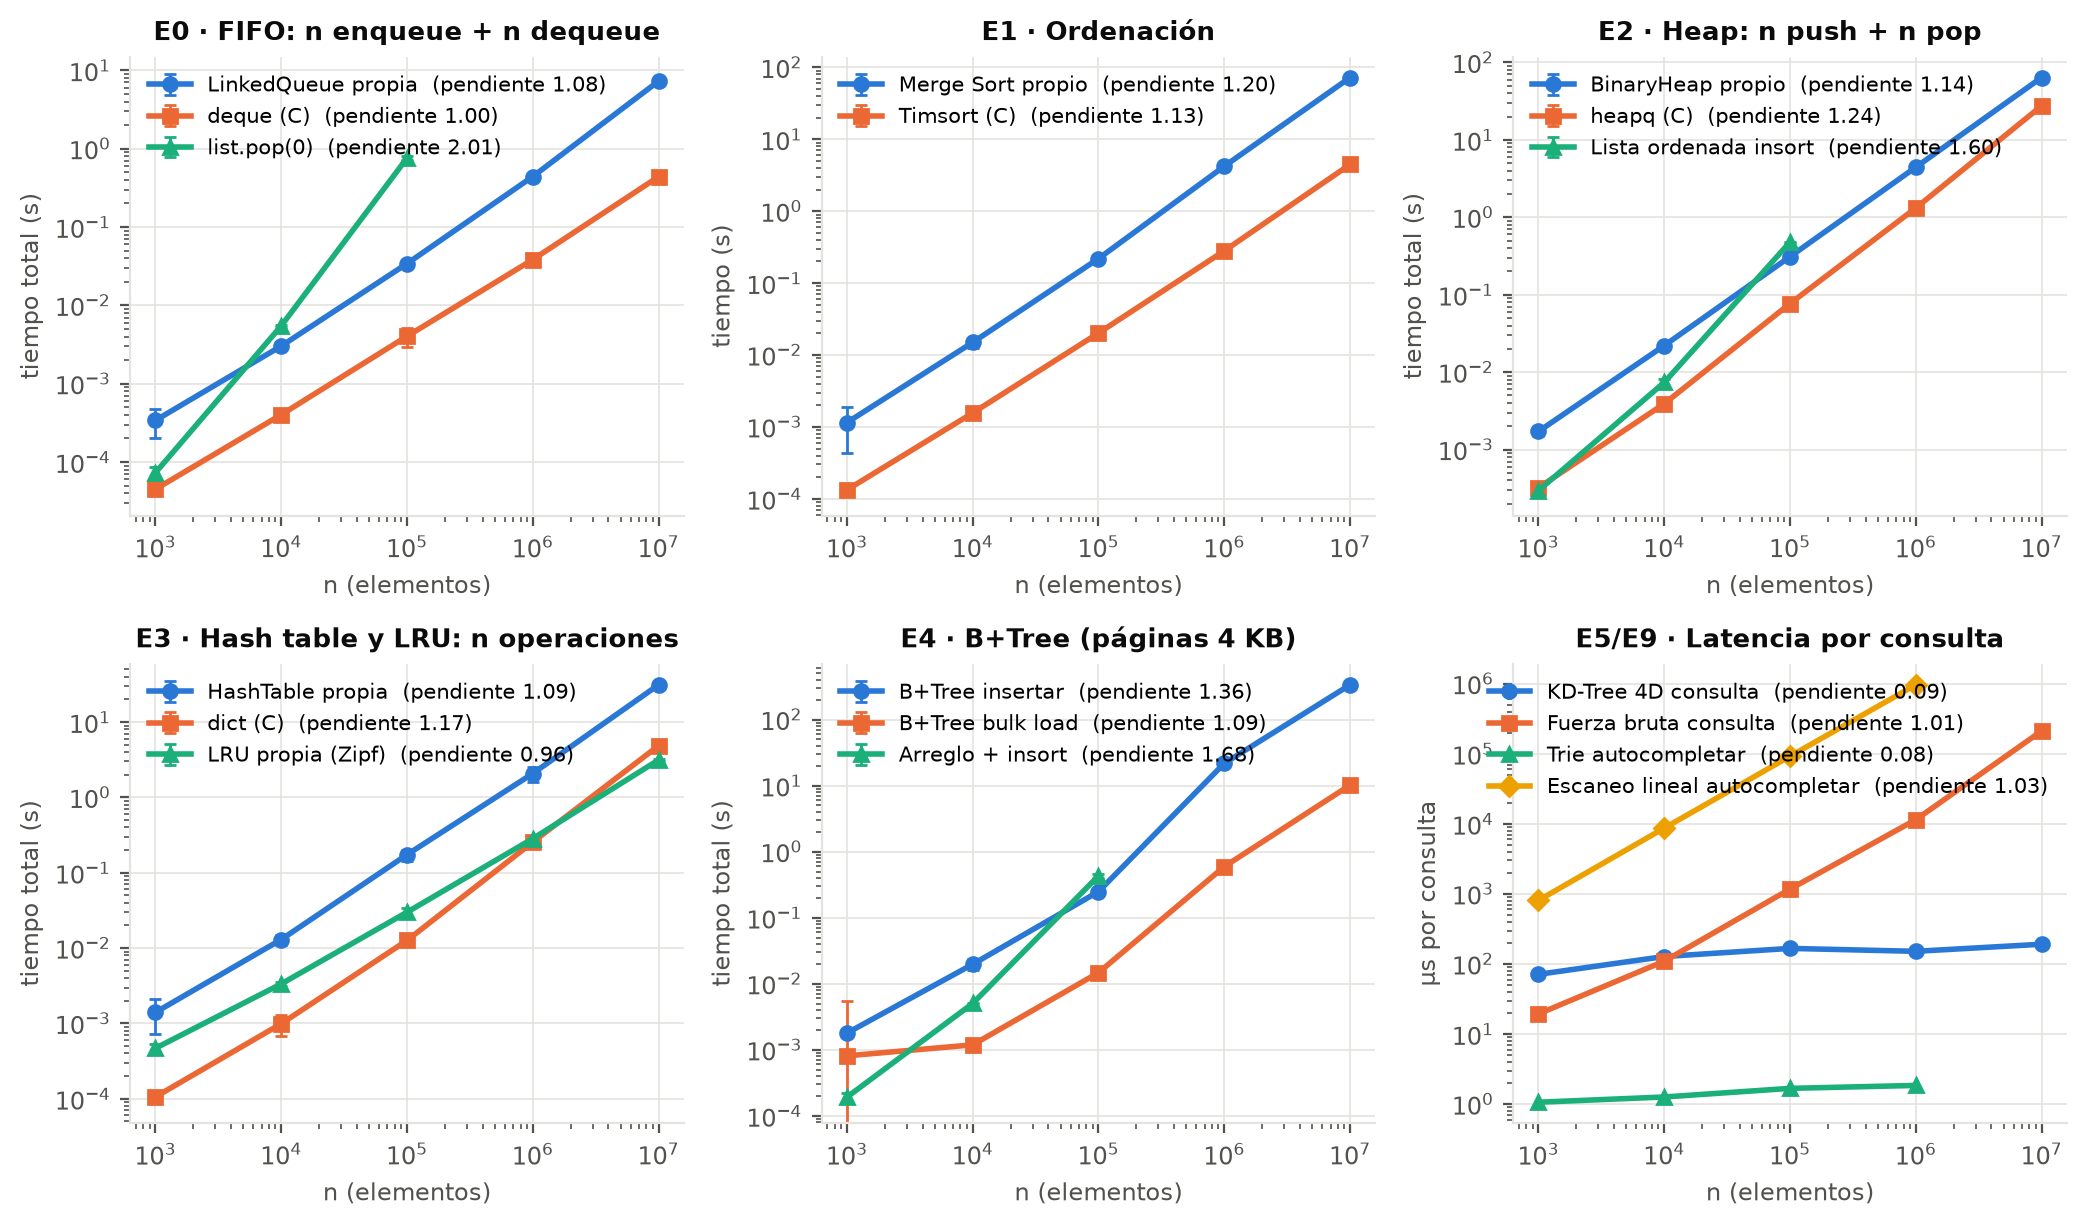

fig_base_memoria


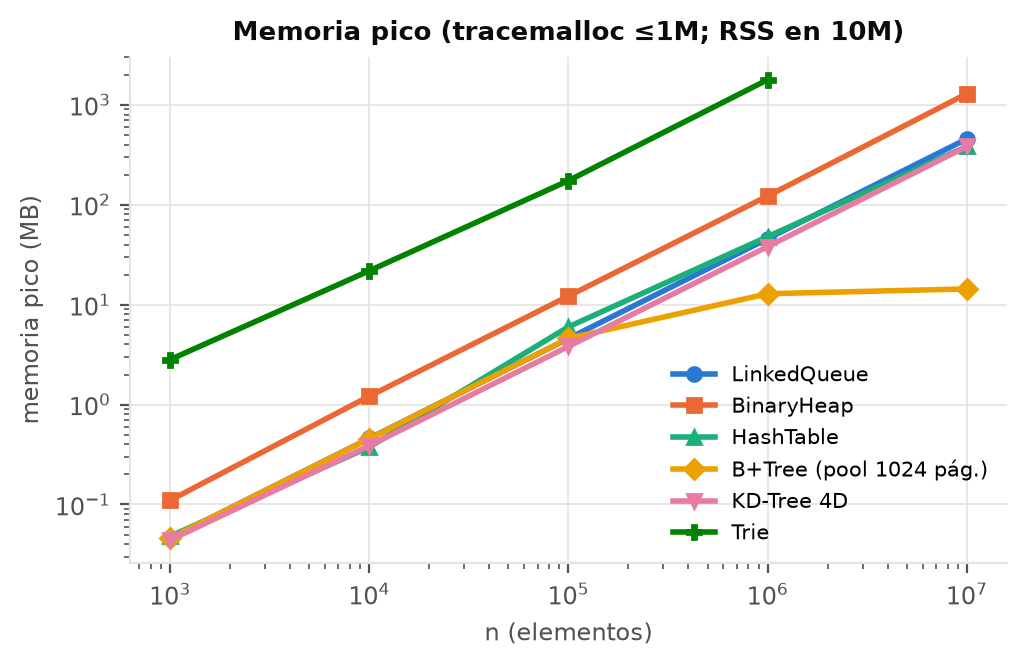

fig_probabilisticas


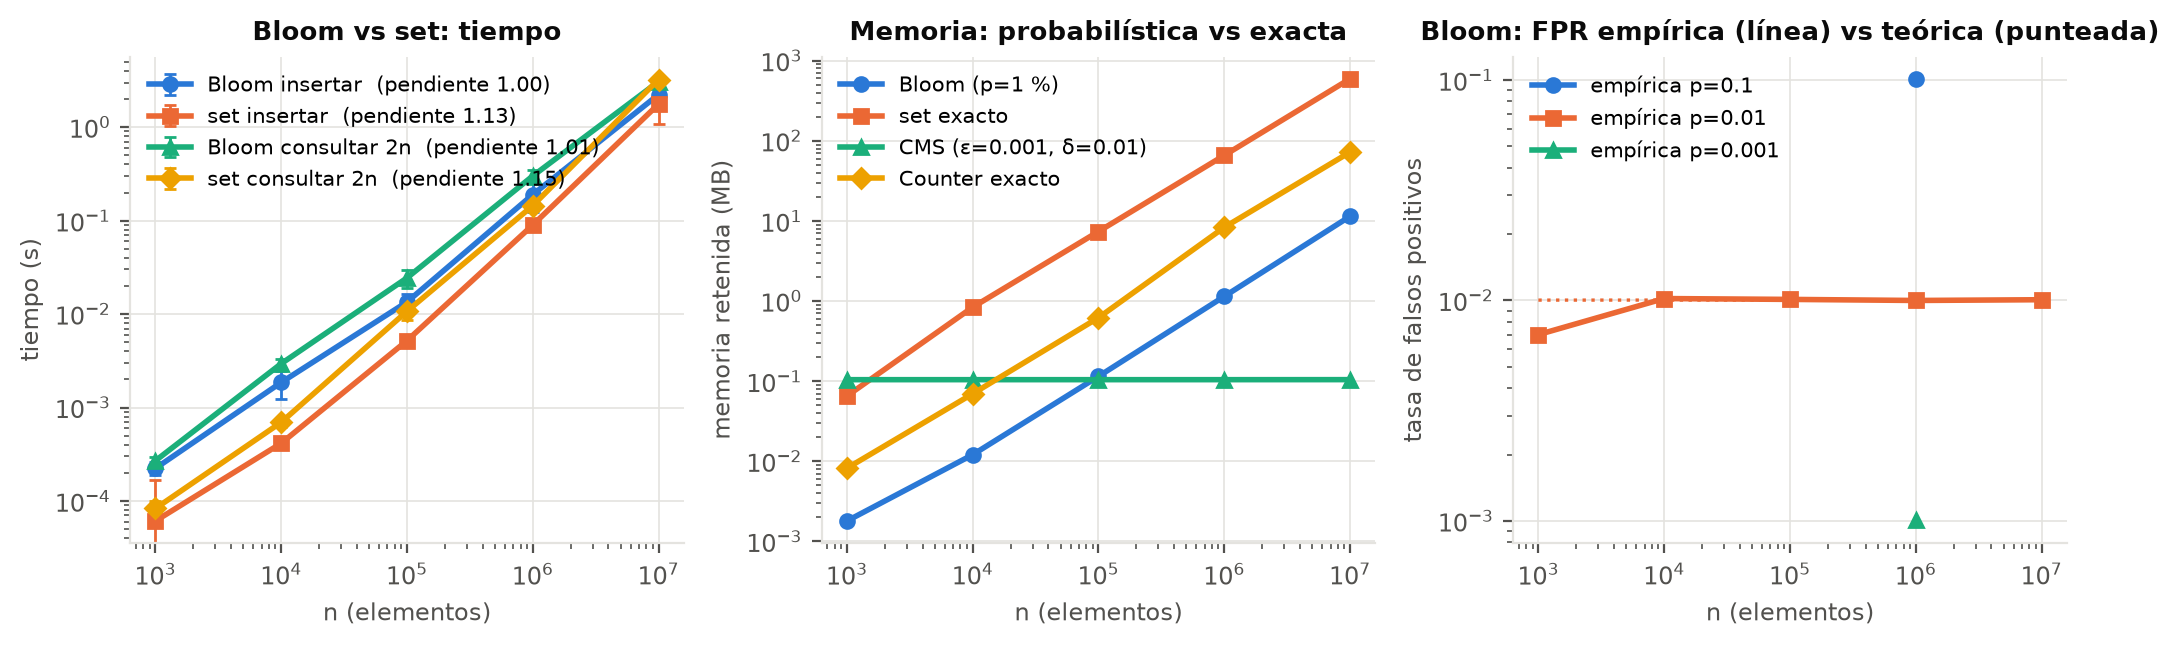

fig_lsh_curva


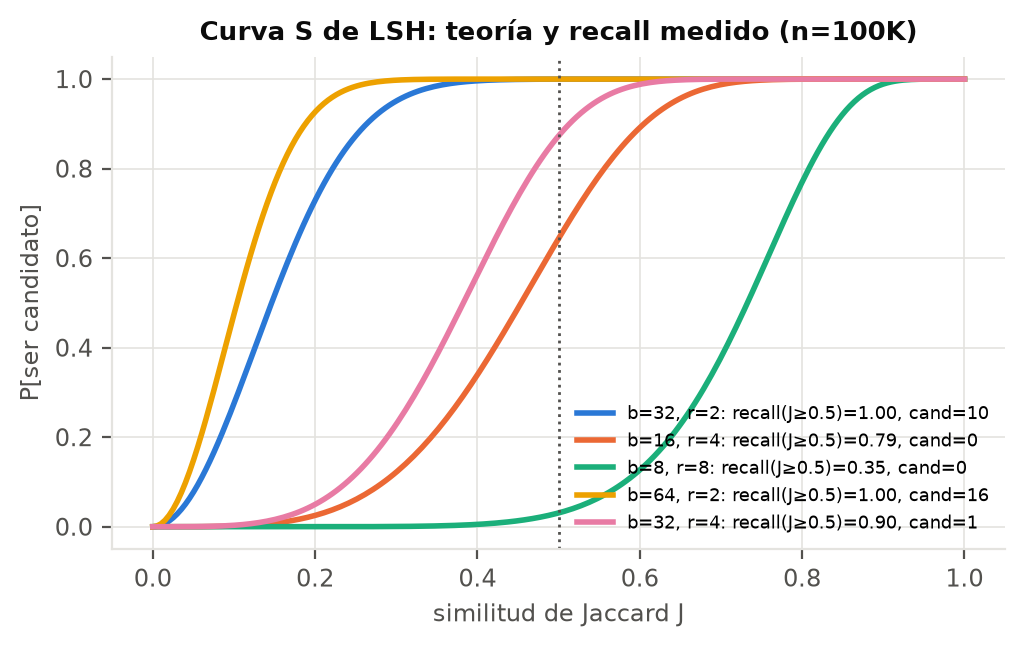

fig_similitud


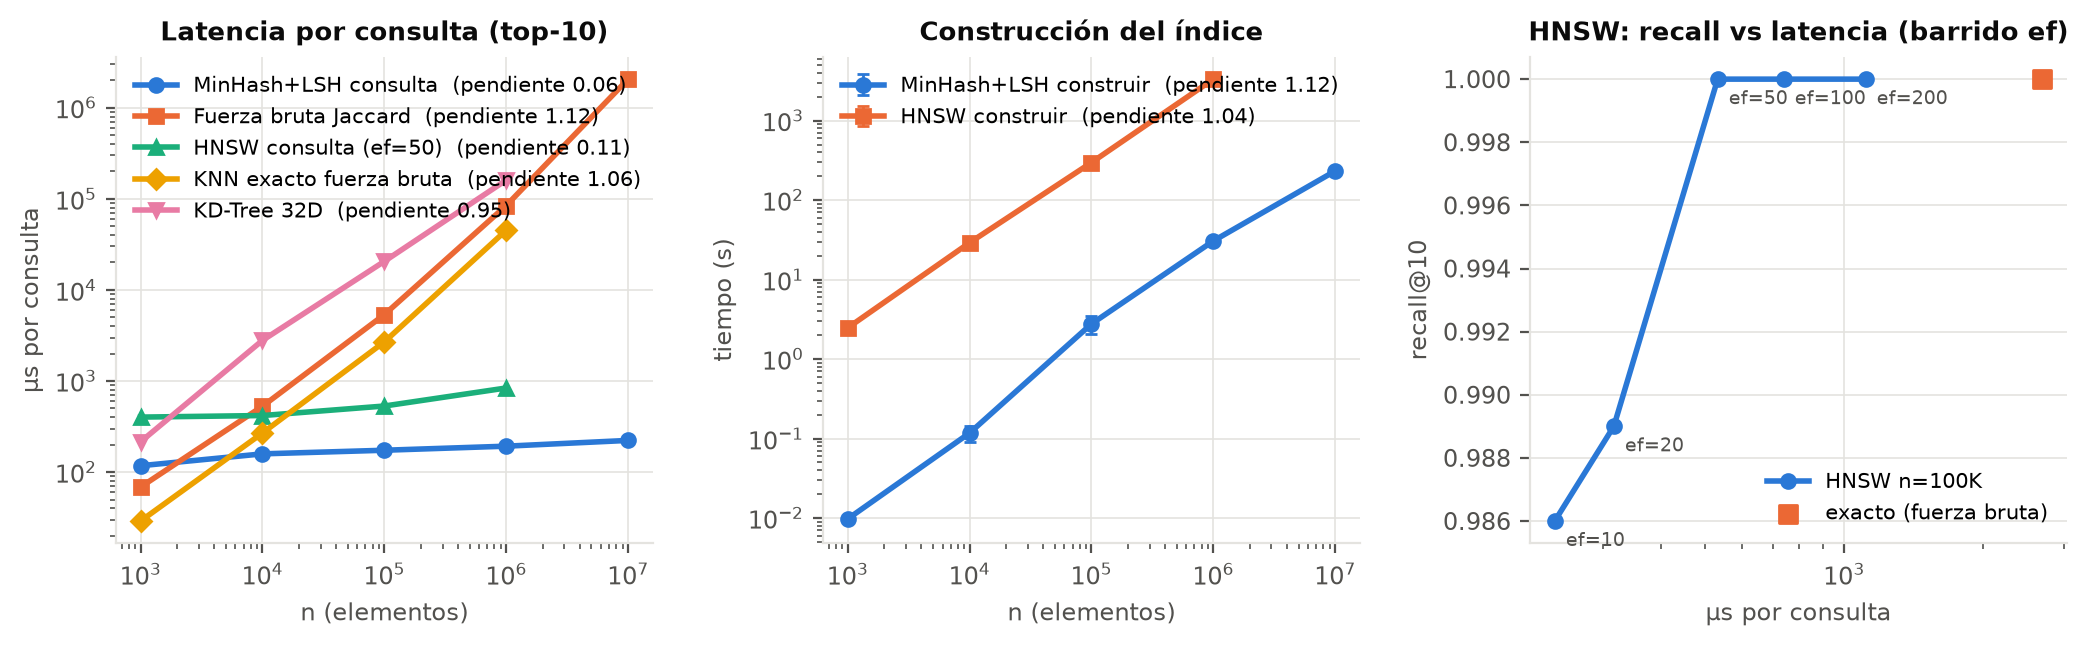

fig_grafo


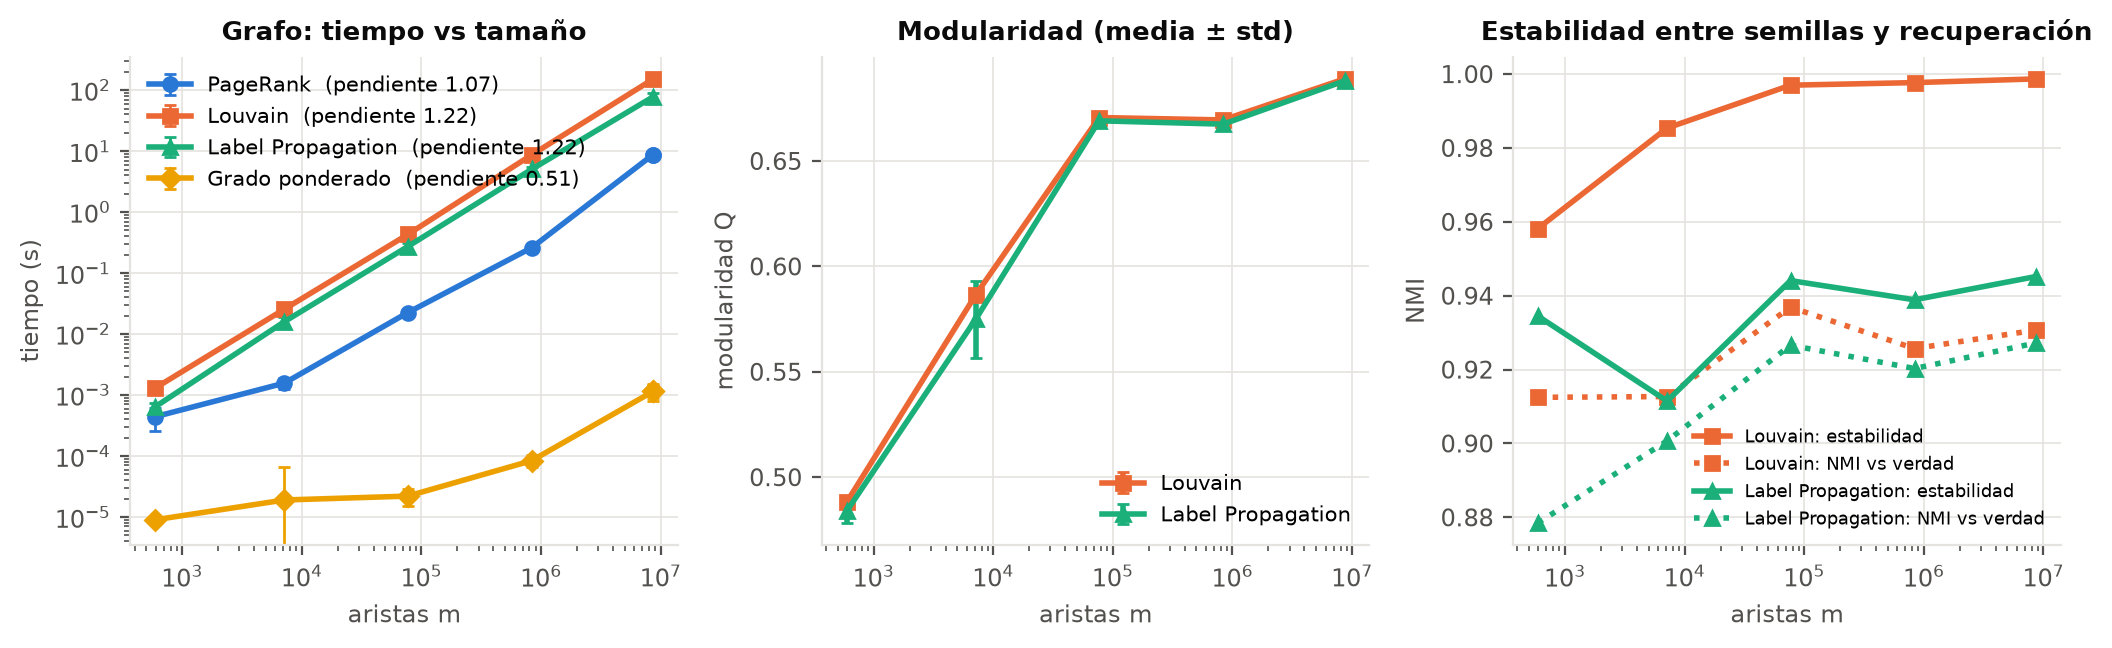

fig_pipeline


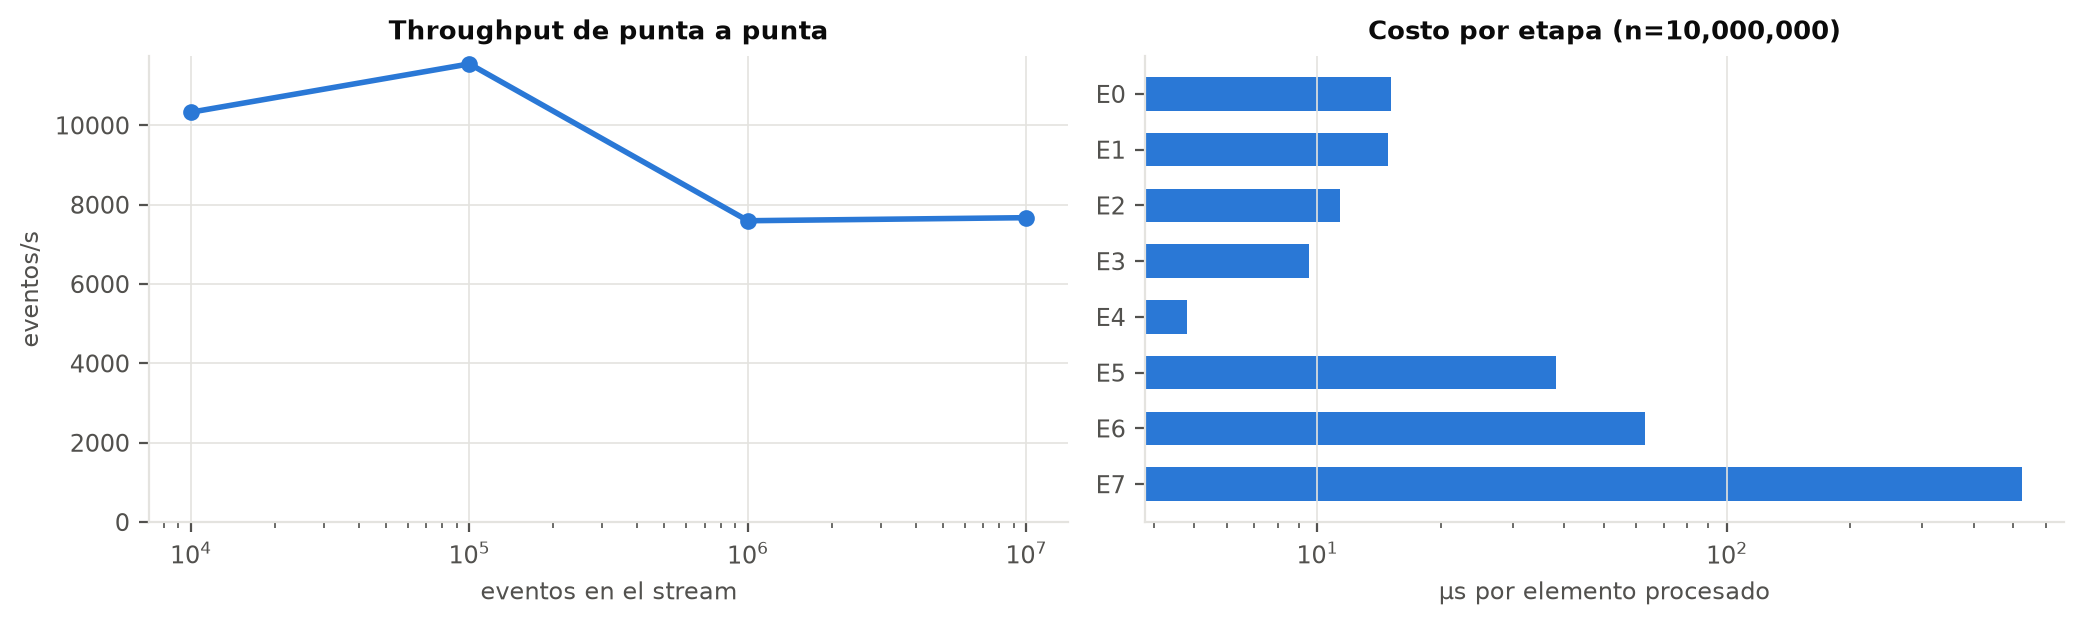

In [4]:
from IPython.display import Image, display
for f in ['fig_base_loglog', 'fig_base_memoria', 'fig_probabilisticas', 'fig_lsh_curva', 'fig_similitud', 'fig_grafo', 'fig_pipeline']:
    path = ROOT / 'experiments/figures' / f'{f}.png'
    if path.exists():
        print(f); display(Image(filename=str(path), width=900))

## Tablas

In [5]:
cols = ['estructura', 'operacion', 'n', 'reps', 'media_s', 'std_s', 'us_por_op', 'mem_actual_mb', 'mem_pico_mb']
pd.read_csv(ROOT / 'experiments/results/base.csv')[cols]

,estructura,operacion,n,reps,media_s,std_s,us_por_op,mem_actual_mb,mem_pico_mb
0,LinkedQueue (propia),enqueue+dequeue,1000,100,0.000340,0.000136,0.1699,NaN,NaN
1,LinkedQueue (propia),n encolados (memoria),1000,100,0.000187,0.000024,0.1865,0.046,0.046
2,collections.deque (ref.),enqueue+dequeue,1000,100,0.000045,0.000007,0.0224,NaN,NaN
3,list.pop(0) (ingenua),enqueue+dequeue,1000,100,0.000073,0.000013,0.0366,NaN,NaN
4,LinkedQueue (propia),enqueue+dequeue,10000,100,0.003024,0.000202,0.1512,NaN,NaN
...,...,...,...,...,...,...,...,...,...
124,KD-Tree 4D (propio),KNN k=10,10000000,3,0.019127,0.000689,191.2660,NaN,NaN
125,KNN fuerza bruta (NumPy),KNN k=10,10000000,2,21.101045,0.108482,211010.4480,NaN,NaN
126,Trie top-K cacheado (propio),insertar,1000000,3,85.880980,10.380858,85.8810,1786.340,1786.340
127,Trie top-K cacheado (propio),autocompletar k=8,1000000,100,0.001848,0.000100,1.8480,NaN,NaN


In [6]:
pd.read_csv(ROOT / 'experiments/results/probabilisticas.csv')

,estructura,operacion,n,p_objetivo,reps,media_s,std_s,us_por_op,mem_actual_mb,mem_pico_mb,...,w,d,claves_distintas,subestimaciones,error_abs_medio,error_max,cota_eps_N,frac_dentro_cota,error_rel_top100,error_rel_medio
0,Bloom Filter (vectorizado),insertar,1000,0.010,100,0.000223,0.000035,0.2230,0.0018,0.1796,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Bloom Filter (vectorizado),consultar 2n,1000,0.010,100,0.000269,0.000027,0.1343,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,set de Python (exacto),insertar,1000,0.000,100,0.000061,0.000106,0.0611,0.0653,0.0808,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,set de Python (exacto),consultar 2n,1000,0.000,100,0.000083,0.000016,0.0414,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"Bloom Filter (escalar, Python)",insertar,1000,0.010,20,0.002820,0.000248,2.8205,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Count-Min Sketch (vectorizado),actualizar stream,1000,NaN,100,0.000166,0.000026,0.1658,0.1045,0.2851,...,2719.0,5.0,100.0,0.0,0.000,0.0,1.0,1.0,0.00000,0.0000
6,Counter/dict (exacto),actualizar stream,1000,NaN,100,0.000071,0.000012,0.0709,0.0082,0.0480,...,NaN,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,"Count-Min Sketch (escalar, Python)",actualizar stream,1000,NaN,20,0.002599,0.000174,2.5990,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Bloom Filter (vectorizado),insertar,10000,0.010,100,0.001854,0.000629,0.1854,0.0121,1.6815,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Bloom Filter (vectorizado),consultar 2n,10000,0.010,100,0.002945,0.000375,0.1473,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
pd.read_csv(ROOT / 'experiments/results/similitud.csv')

,estructura,operacion,n,reps,media_s,std_s,us_por_op,mem_actual_mb,mem_pico_mb,umbral,recall_J05,recall_top10,candidatos_prom,frac_comparada,construir_s,niveles,recall_10,nodos_visitados,nodos_totales
0,"MinHash+LSH (k=64, b=32, r=2)",construir indice,1000,20,0.009750,0.000570,9.749,0.38,10.38,0.177,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"MinHash+LSH (k=64, b=32, r=2)",consulta top-10,1000,100,0.011758,0.001765,117.580,NaN,NaN,NaN,1.0000,0.1886,1.6,0.001630,NaN,NaN,NaN,NaN,NaN
2,"Fuerza bruta Jaccard (NumPy, O(nnz))",consulta top-10,1000,20,0.006866,0.000764,68.660,0.05,NaN,NaN,1.0000,1.0000,1000.0,NaN,NaN,NaN,NaN,NaN,NaN
3,"MinHash+LSH (k=64, b=32, r=2)",construir indice,10000,20,0.117390,0.027640,11.739,3.67,103.90,0.177,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"MinHash+LSH (k=64, b=32, r=2)",consulta top-10,10000,100,0.015871,0.002166,158.710,NaN,NaN,NaN,1.0000,0.2350,8.0,0.000800,NaN,NaN,NaN,NaN,NaN
5,"Fuerza bruta Jaccard (NumPy, O(nnz))",consulta top-10,10000,20,0.052872,0.007928,528.720,0.46,NaN,NaN,1.0000,1.0000,10000.0,NaN,NaN,NaN,NaN,NaN,NaN
6,"MinHash+LSH (k=64, b=32, r=2)",construir indice,100000,9,2.769350,0.684610,27.694,36.63,1035.37,0.177,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,"MinHash+LSH (k=64, b=32, r=2)",consulta top-10,100000,100,0.017388,0.003269,173.880,NaN,NaN,NaN,1.0000,0.2520,9.8,0.000098,NaN,NaN,NaN,NaN,NaN
8,"Fuerza bruta Jaccard (NumPy, O(nnz))",consulta top-10,100000,20,0.535906,0.019926,5359.060,4.58,NaN,NaN,1.0000,1.0000,100000.0,NaN,NaN,NaN,NaN,NaN,NaN
9,"MinHash+LSH (k=64, b=32, r=2)",construir indice,1000000,3,30.637030,2.496710,30.637,366.22,2877.30,0.177,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
pd.read_csv(ROOT / 'experiments/results/grafo.csv')

,algoritmo,n,nodos,aristas,reps,media_s,std_s,iteraciones,us_por_arista_iter,mem_actual_mb,...,modularidad_std,comunidades,comunidades_std,mayor,mediana,singletons,frac_mayor,estabilidad_nmi,nmi_vs_plantadas,tamanos_top10
0,PageRank (iteración de potencias),1000,125,594,100,0.000441,0.000183,42.0,0.0177,0.001,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Ranking por grado ponderado,1000,125,594,100,0.000009,0.000001,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Louvain,1000,125,594,10,0.001300,0.000100,NaN,NaN,0.010,...,0.00088,5.0,0.00,58.0,21.0,0.0,0.4640,0.9582,0.9125,"[58, 22, 21, 14, 10]"
3,Label Propagation,1000,125,594,10,0.000640,0.000100,NaN,NaN,0.070,...,0.00545,5.0,0.00,59.0,21.0,0.0,0.4720,0.9345,0.8785,"[59, 22, 21, 12, 11]"
4,PageRank (iteración de potencias),10000,1250,7146,100,0.001570,0.000334,38.0,0.0058,0.010,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Ranking por grado ponderado,10000,1250,7146,100,0.000019,0.000047,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Louvain,10000,1250,7146,10,0.025610,0.004700,NaN,NaN,0.020,...,0.00017,17.0,0.00,310.0,54.0,0.0,0.2486,0.9854,0.9127,"[310, 182, 93, 65, 63, 58, 57, 56, 54, 46]"
7,Label Propagation,10000,1250,7146,10,0.015960,0.003230,NaN,NaN,0.120,...,0.01832,19.0,1.35,333.0,47.0,0.0,0.2670,0.9115,0.9007,"[333, 180, 96, 67, 65, 57, 54, 51, 47, 47]"
8,PageRank (iteración de potencias),100000,12500,76778,100,0.022477,0.001941,39.0,0.0075,0.096,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Ranking por grado ponderado,100000,12500,76778,100,0.000022,0.000007,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
pd.read_csv(ROOT / 'experiments/results/pipeline.csv')

,n,eventos_procesados,reps,setup_s,run_s,total_s,throughput_ev_s,rss_pico_mb,ordenes_aprobadas,ordenes_bloqueadas,...,E5_us,E6_s,E6_us,E7_s,E7_us,E8_s,E8_us,E9_s,E9_us,espera_ticks
0,10000,9996,1,40.72,0.97,41.69,10333,115.4,348,2,...,55.86,0.0488,90.59,39.6163,52126.71,0.1252,NaN,0.0239,NaN,"{""alerta"": 0.0, ""pago"": 0.0, ""compra_express/premium"": 0.0, ""compra_estandar..."
1,100000,99901,1,40.65,8.65,49.30,11551,196.6,3480,17,...,37.19,0.3629,99.22,40.4522,5466.51,1.3851,NaN,0.5400,NaN,"{""alerta"": 0.0, ""pago"": 0.0, ""compra_express/premium"": 0.0, ""compra_estandar..."
2,1000000,999061,1,42.93,131.52,174.44,7597,1084.5,34808,146,...,37.37,2.8069,77.85,76.9014,1023.06,10.5509,NaN,8.6915,NaN,"{""alerta"": 0.0, ""pago"": 0.0, ""compra_express/premium"": 0.0, ""compra_estandar..."
3,10000000,9990165,1,55.38,1301.85,1357.23,7674,4573.8,348074,1405,...,38.26,22.7002,63.09,394.8082,525.81,21.1117,NaN,14.9299,NaN,"{""alerta"": 0.0, ""pago"": 0.0, ""compra_express/premium"": 0.0, ""compra_estandar..."


In [10]:
pd.read_csv(ROOT / 'experiments/results/pendientes.csv')

,estructura/operación,metrica,pendiente_ajustada,esperada,n_min,n_max
0,LinkedQueue propia,media_s,1.082,"1 (O(n) total, O(1)/op)",1000,10000000
1,deque (C),media_s,0.996,1,1000,10000000
2,list.pop(0),media_s,2.008,2 (O(n²)),1000,100000
3,Merge Sort propio,media_s,1.205,≈1.05-1.1 (n log n),1000,10000000
4,Timsort (C),media_s,1.131,≈1.05-1.1 (n log n),1000,10000000
5,BinaryHeap propio,media_s,1.145,≈1.05-1.1 (n log n),1000,10000000
6,heapq (C),media_s,1.239,≈1.05-1.1,1000,10000000
7,Lista ordenada insort,media_s,1.605,2 (O(n²) memmove),1000,100000
8,HashTable propia,media_s,1.090,1 (O(1)/op),1000,10000000
9,dict (C),media_s,1.173,1,1000,10000000
